In [ ]:
# Colab > Colab CPU > terminal
# mkdir data
# cd data
# wget https://github.com/code-archive-git/ai/raw/refs/heads/main/production/data/continuous_factory_process.csv

In [2]:
# ① 데이터 불러오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# parse_dates=['time_stamp'] : 판다스(Pandas)가 날짜형 데이터(datetime64) 타입으로 정확하게 인식하도록 변환
df = pd.read_csv('/content/data/continuous_factory_process.csv', parse_dates=['time_stamp'])
df.head() # 컬럼명이 너무 길다.


,time_stamp,AmbientConditions.AmbientHumidity.U.Actual,AmbientConditions.AmbientTemperature.U.Actual,Machine1.RawMaterial.Property1,Machine1.RawMaterial.Property2,Machine1.RawMaterial.Property3,Machine1.RawMaterial.Property4,Machine1.RawMaterialFeederParameter.U.Actual,Machine1.Zone1Temperature.C.Actual,Machine1.Zone2Temperature.C.Actual,...,Stage2.Output.Measurement10.U.Actual,Stage2.Output.Measurement10.U.Setpoint,Stage2.Output.Measurement11.U.Actual,Stage2.Output.Measurement11.U.Setpoint,Stage2.Output.Measurement12.U.Actual,Stage2.Output.Measurement12.U.Setpoint,Stage2.Output.Measurement13.U.Actual,Stage2.Output.Measurement13.U.Setpoint,Stage2.Output.Measurement14.U.Actual,Stage2.Output.Measurement14.U.Setpoint
0,2019-03-06 10:52:33,17.24,23.53,11.54,200,963.0,247,1241.26,72.0,72.3,...,0.0,7.93,0.0,5.65,0.0,1.85,0.0,2.89,0.0,11.71
1,2019-03-06 10:52:34,17.24,23.53,11.54,200,963.0,247,1246.09,72.0,72.3,...,0.0,7.93,0.0,5.65,0.0,1.85,0.0,2.89,0.0,11.71
2,2019-03-06 10:52:35,17.24,23.53,11.54,200,963.0,247,1246.29,72.0,72.3,...,0.0,7.93,0.0,5.65,0.0,1.85,0.0,2.89,0.0,11.71
3,2019-03-06 10:52:36,17.24,23.53,11.54,200,963.0,247,1247.59,72.0,72.3,...,0.0,7.93,0.0,5.65,0.0,1.85,0.0,2.89,0.0,11.71
4,2019-03-06 10:52:37,17.24,23.53,11.54,200,963.0,247,1252.83,72.1,72.4,...,0.0,7.93,0.0,5.65,0.0,1.85,0.0,2.89,0.0,11.71


In [3]:
# 이름을 줄이기 위한 함수 선언
def short(c):                       # 긴 컬럼명을 읽기 쉽게 줄인다
    return (c.replace('AmbientConditions.Ambient', 'Amb_')
             .replace('FirstStage.CombinerOperation.', 'Comb_')
             .replace('Stage1.Output.Measurement', 'S1_Out')
             .replace('RawMaterialFeederParameter', 'Feeder')
             .replace('RawMaterial.', 'Raw_')
             .replace('Machine', 'M')
             .replace('.U.Actual', '_U').replace('.C.Actual', '_C')
             .replace('.', '_'))

In [4]:
df = df.rename(columns=short)
UP = list(df.columns[1:42])         # 상류 변수 41개 : 주변환경 2 + Machine1~3 36 + Combiner 3
TARGET = 'S1_Out0_U'                # 예측 대상 : 1단계 품질 측정값 Measurement0

print(df.shape)
print(df[TARGET].describe().round(3))

# 기기 측정 시간
print("시작 시간:", df['time_stamp'].min())
print("종료 시간:", df['time_stamp'].max())



(14088, 116)
count    14088.000
mean        12.897
std          0.934
min          0.000
25%         12.890
50%         12.970
75%         13.050
max         20.880
Name: S1_Out0_U, dtype: float64
시작 시간: 2019-03-06 10:52:33
종료 시간: 2019-03-06 14:47:20


In [5]:
# ② 센서 이상값 처리
print('0 값 비율 :', round((df[TARGET] == 0).mean(), 4))
# 조건이 True 면 그대로 유지하고, False 면 결측(NaN) 처리 해라
df[TARGET] = df[TARGET].where((df[TARGET] > 12) & (df[TARGET] < 14))   # 범위 밖은 결측 처리
print('결측 처리 비율 :', round(df[TARGET].isna().mean(), 4))

0 값 비율 : 0.005
결측 처리 비율 : 0.0057


[12.773, 12.787, 12.861, 13.101, 12.894, 13.036, 13.043, 13.053, 13.059, 13.078, 12.965, 12.961, 12.955, 12.928, 12.894, 12.894]


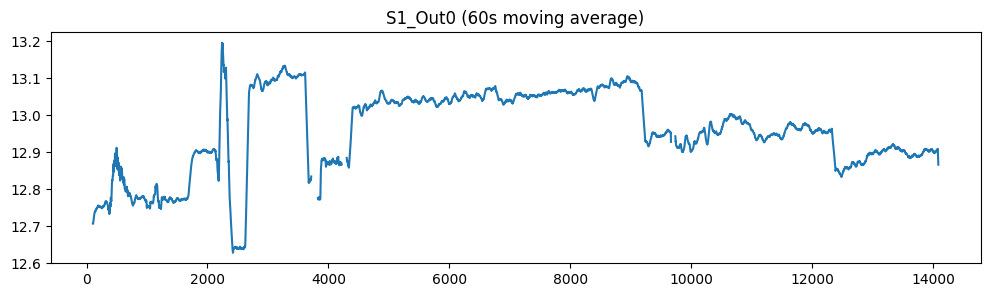

In [6]:
# ③ 시간 추이 확인
# 매초를 900 단위(15분)로 묶어서 평균을 낸다.
trend = df.groupby(df.index // 900)[TARGET].mean()
# 그리고 리스트로 반환
print(trend.round(3).tolist())

# 1분 단위로 이동평균을 만들어 그려본다.
df[TARGET].rolling(60).mean().plot(figsize=(12, 3), title='S1_Out0 (60s moving average)')
plt.show()

In [7]:
# ④ 상관분석
# 상류 센서(UP)와 타겟 치수(TARGET)를 모아서 서로 간의 상관계수(밀접한 정도)를 구한 뒤, 
# drop(TARGET) : 타겟과 타겟과의 관계는 어차피 1 이므로 삭제
corr = df[UP + [TARGET]].corr()[TARGET].drop(TARGET)
# 절대값으로 내림차순 한 다음 인덱싱을 다시 하여 10개만 뽑아낸다.
top10 = corr.reindex(corr.abs().sort_values(ascending=False).index).head(10)
print(top10.round(3)) # 소숫점 3자리 제한

M3_MaterialTemperature_U    0.576
M2_Raw_Property4           -0.503
M2_Raw_Property3           -0.503
M2_Raw_Property1            0.503
M2_Raw_Property2            0.503
M2_MaterialTemperature_U    0.429
Amb_Temperature_U          -0.390
M2_MotorAmperage_U          0.380
M2_MaterialPressure_U      -0.325
M1_Zone1Temperature_C      -0.306
Name: S1_Out0_U, dtype: float64


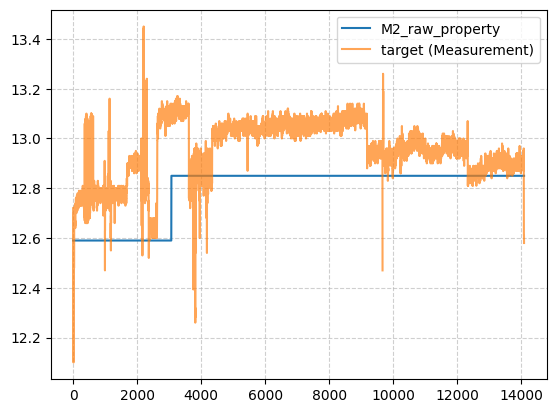

In [8]:
# 3. [로트 고정값 검증] M2 원자재 속성이 계단식으로 변하는지 시각화
plt.plot(df.index, df["M2_Raw_Property1"], label="M2_raw_property")
plt.plot(df.index, df[TARGET], alpha=0.7, label="target (Measurement)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

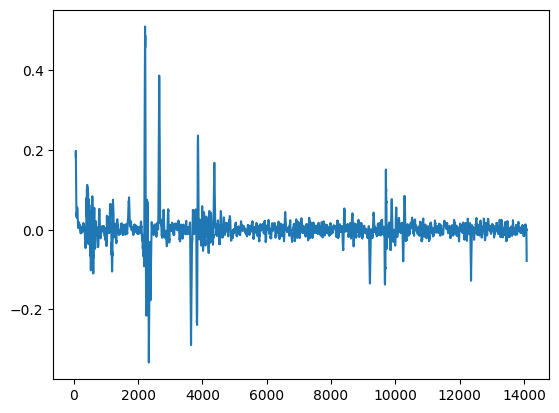

In [9]:
# ⑤ 시차별 상관 (Cross-correlation)        
# 측정치를 보간법으로 부드럽게 이어서 30개 이동평균을 만들어 30행 전 데이터와 차이를 저장
dy = df[TARGET].interpolate().rolling(30).mean().diff(30)       
plt.plot(dy)
plt.show()

In [10]:
rows = {}
# Row_Prop 에 해당되지 않는, 센서컬럼만 뽑아온다.
for c in [c for c in UP if 'Raw_Prop' not in c] :
    # 센서별 30개 행(시점) 이동 평균을 구한 뒤, 그 값의 30개 시점 전과의 변화량을 계산하여 dx에 저장
    dx = df[c].rolling(30).mean().diff(30)
    map = {}
    # 0부터 120까지 5 간격으로...
    for k in range(0,121,5):
        # k만큼 밀어가며, 품질 측정값의 변화량(dy)과의 상한계수(corr)를 계산
        val = dx.shift(k).corr(dy)
        # 맵에 담은 다음
        map[k] = val
    # 시리즈에 저장
    r = pd.Series(map)
    # 계산된 상관계수(r)의 절댓값이 가장 큰 값의 인덱스(idxmax())를 찾아 best 변수에 저장
    best = r.abs().idxmax()

    # 센서 이름(c)을 키(Key)로 하여, 
    # 가장 상관관계가 높은 최적의 시차(best_lag(초)), 
    # 그때의 상관계수(r_best), 
    # 시차가 0초일 때의 기본 상관계수(r_lag0)를 딕셔너리 형태로 묶어 rows에 저장
    rows[c] = {'best_lag(초)': best, 'r_best': r[best], 'r_lag0': r[0]}

# 결과를 dataFrame 으로 저장 
result_df = pd.DataFrame(rows)

# result_df.T <- pivot 처럼 행과 열을 바꾼다.
# 최적 상관계수(r_best)의 절댓값이 큰 순서(key=abs, ascending=False)로 내림차순 정렬하여 lag_tbl을 만듭니다.
lag_tbl = result_df.T.sort_values('r_best', key=abs, ascending=False)
print(lag_tbl.head(5).round(3))

                          best_lag(초)  r_best  r_lag0
Comb_Temperature1_U              10.0  -0.214  -0.128
M2_MotorAmperage_U               15.0   0.214   0.074
M3_MaterialPressure_U             0.0  -0.110  -0.110
M3_MaterialTemperature_U          0.0   0.097   0.097
M1_MaterialPressure_U             5.0  -0.096  -0.083


In [13]:
from sklearn.model_selection import cross_validate, GroupKFold
from xgboost import XGBRegressor

PROC = [c for c in UP if "Raw_Prop" not in c]

def evaluate(F, name):
    D = F.assign(y=df[TARGET]).dropna()
    groups = D.index // 600                           # 10분 단위 블록 (3단계에서 설명)
    m = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=0)
    r = cross_validate(m, D.drop(columns='y'), D['y'], cv=GroupKFold(5), groups=groups,
                       scoring=('neg_root_mean_squared_error', 'r2'))
    return {'특징셋': name, '변수 수': F.shape[1],
            'RMSE': -r['test_neg_root_mean_squared_error'].mean(), 'R2': r['test_r2'].mean()}

F_all  = df[UP]                                                   # A. 상류 전체
F_proc = df[PROC]                                                 # B. 원자재 속성 제외
F_lag  = F_proc.assign(M2_MotorAmperage_U_lag15=df['M2_MotorAmperage_U'].shift(15),
                       Comb_Temperature1_U_lag10=df['Comb_Temperature1_U'].shift(10))   # C. + 시차
F_ma   = pd.concat([F_proc, F_proc.rolling(60).mean().add_suffix('_ma60')], axis=1)     # D. + 이동평균

fe_result = pd.DataFrame([evaluate(F_all, 'A. 상류 전체'), evaluate(F_proc, 'B. 원자재 속성 제외'),
                          evaluate(F_lag, 'C. B + 시차'), evaluate(F_ma, 'D. B + 이동평균')])
fe_result.round(4)

,특징셋,변수 수,RMSE,R2
0,A. 상류 전체,41,0.0914,0.3955
1,B. 원자재 속성 제외,29,0.0881,0.4383
2,C. B + 시차,31,0.0931,0.1843
3,D. B + 이동평균,58,0.0977,0.0944
